# **FINAL EXAM DEEP LEARNING**

**NO 2**  
**Nama  : Stevanus Gerald Marconus**  
**NIM   : 2802392500**

**Lampiran:**  
Link -> https://youtu.be/JA0EwTsHGQM 

In [1]:
!pip install scikit-image -q

In [2]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim
SEED = 1234
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {device}')

Device  : cuda


### **A. Lakukan loading dan scaling data serta tampilkan contoh data yang digunakan. Kemudian pisahkan dataset menjadi 80% training set, 10% validation set dan 10% test set.**

#### **A.1 Import Data and Overview**

In [4]:
SOURCE_DIR = '.'
TARGET_CLASSES = ['Storage Tanks', 'Parking Lot']
IMG_SIZE = 28

In [5]:
def find_folders(root, target_classes):
    def norm(s): return s.lower().replace('_',' ').replace('-',' ').strip()
    def keywords(s): return frozenset(w.rstrip('s') for w in norm(s).split())
    target_kw = {keywords(c): c for c in target_classes}
    found = {}
    candidates = []
    if os.path.isdir(root):
        for item in os.listdir(root):
            full = os.path.join(root, item)
            if os.path.isdir(full) and item.lower() in ('train','test','training','testing'):
                candidates.append(full)
        candidates.append(root)
    for base in candidates:
        for d in os.listdir(base):
            full = os.path.join(base, d)
            if os.path.isdir(full) and keywords(d) in target_kw:
                found.setdefault(target_kw[keywords(d)], []).append(full)
    return found

In [6]:
folders = find_folders(SOURCE_DIR, TARGET_CLASSES)
print('Folder kelas yang ditemukan:')
for cls, paths in folders.items():
    print(f'  {cls}:')
    for p in paths: print(f'    - {p}')

if len(folders) < 2:
    print("PERINGATAN: Tidak semua kelas ditemukan!")
    print(f"Isi DATA_ROOT: {os.listdir(SOURCE_DIR) if os.path.isdir(SOURCE_DIR) else "folder tidak ada"}")

Folder kelas yang ditemukan:
  Storage Tanks:
    - .\Train\storage_tank
    - .\Test\storage_tank
  Parking Lot:
    - .\Train\parking_lot
    - .\Test\parking_lot


#### **A.2 Load Data**

In [7]:
def load(folder_dict, img_size=28):
    images, labels = [], []
    class_names = sorted(folder_dict.keys())
    for idx, cls in enumerate(class_names):
        for folder in folder_dict[cls]:
            for ext in ['*.png','*.jpg','*.jpeg','*.bmp']:
                for fp in glob.glob(os.path.join(folder, ext)):
                    try:
                        img = Image.open(fp).convert('L').resize((img_size,img_size))
                        images.append(np.array(img, dtype=np.float32))  # mentah 0-255
                        labels.append(idx)
                    except Exception: pass
    return np.array(images), np.array(labels), class_names

In [8]:
X_raw, y, class_names = load(folders, IMG_SIZE)

Images per class:
  Parking Lot: 8007 images
  Storage Tanks: 8009 images

Total images: 16016


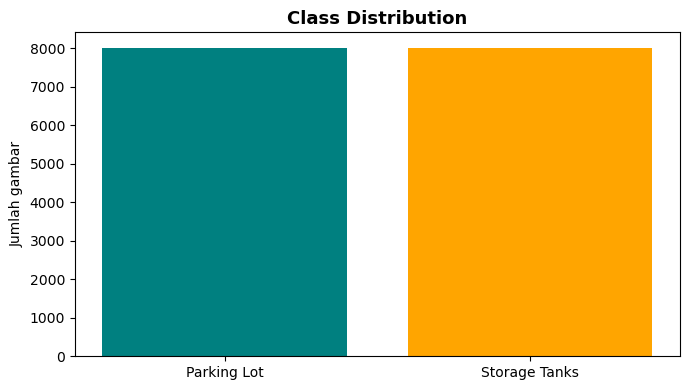

In [9]:
class_counts = {class_names[i]: int((y==i).sum()) for i in range(len(class_names))}
print('Images per class:')
for cls, c in class_counts.items():
    print(f'  {cls}: {c} images')
print(f'\nTotal images: {sum(class_counts.values())}')

plt.figure(figsize=(7,4))
plt.bar(class_counts.keys(), class_counts.values(), color=['teal','orange'])
plt.title('Class Distribution', fontsize=13, fontweight='bold')
plt.ylabel('Jumlah gambar')
plt.tight_layout()
plt.show()

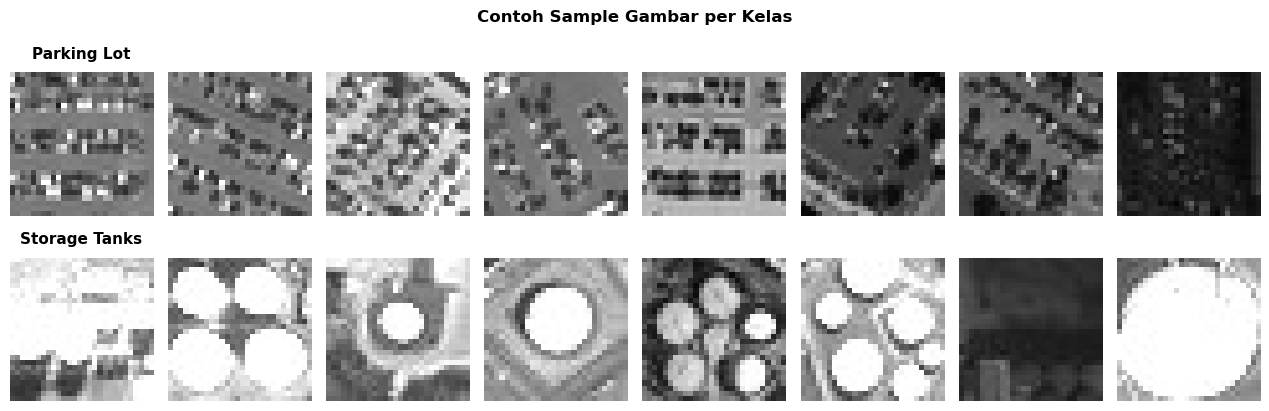

In [10]:
np.random.seed(SEED)
n_per_class = 8
n_classes = len(class_names)
label_names = {
    0: 'Parking Lot',
    1: 'Storage Tanks'
}
fig, axes = plt.subplots(n_classes, n_per_class, figsize=(n_per_class*1.6, n_classes*2.2))
for r in range(n_classes):
    idxs = np.where(y == r)[0]
    if len(idxs) == 0:
        for c in range(n_per_class):
            axes[r, c].axis('off')
        continue
    sel = np.random.choice(idxs, size=min(n_per_class, len(idxs)), replace=False)
    for c, idx in enumerate(sel):
        ax = axes[r, c]
        ax.imshow(X_raw[idx], cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        if c == 0:
            ax.set_title(label_names.get(r, class_names[r]), fontweight='bold', fontsize=11, pad=10)
            ax.set_ylabel(label_names.get(r, class_names[r]), rotation=90, size=11, labelpad=18)
plt.suptitle('Contoh Sample Gambar per Kelas', fontweight='bold')
plt.tight_layout()
plt.show()

#### **A.3 Scalling**

In [11]:
X = X_raw / 255.0
print('Scaling selesai!')
print(f'Range pixel sebelum scaling : [{X_raw.min():.0f}, {X_raw.max():.0f}]')
print(f'Range pixel sesudah scaling : [{X.min():.2f}, {X.max():.2f}]')

Scaling selesai!
Range pixel sebelum scaling : [0, 255]
Range pixel sesudah scaling : [0.00, 1.00]


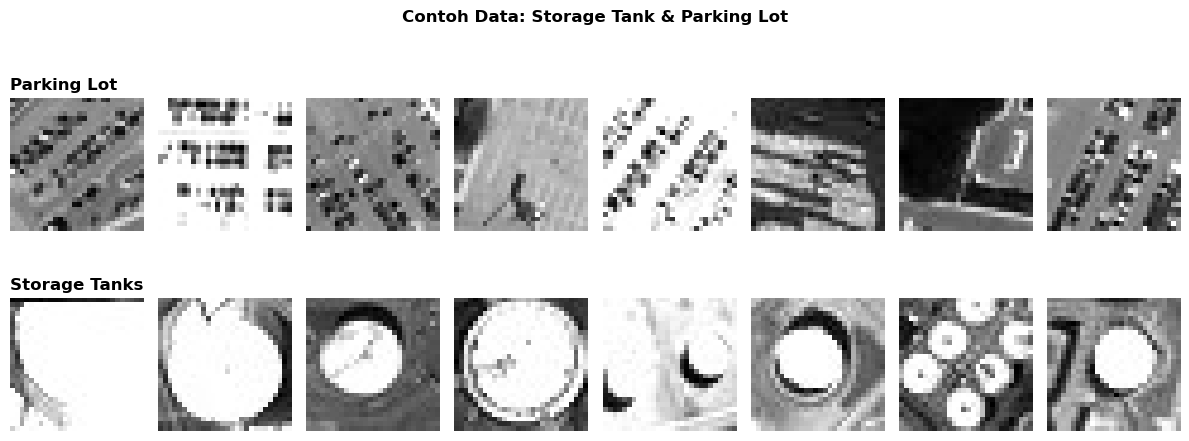

In [12]:
plt.figure(figsize=(12, 5))
for cls_idx in range(len(class_names)):
    idxs = np.where(y == cls_idx)[0][:8]
    for col, idx in enumerate(idxs):
        ax = plt.subplot(len(class_names), 8, cls_idx*8 + col + 1)
        plt.imshow(X[idx], cmap='gray')
        if col == 0:
            plt.title(class_names[cls_idx], loc='left', fontweight='bold')
        plt.axis('off')
plt.suptitle('Contoh Data: Storage Tank & Parking Lot', fontweight='bold')
plt.tight_layout()
plt.show()

Dari contoh data di atas dapat dilihat bahwa kelas **Storage Tank** memiliki ciri bentuk-bentuk melingkar (tangki dari pandangan atas), sedangkan kelas **Parking Lot** memiliki ciri pola garis-garis teratur (marka parkir). Kedua kelas memiliki karakteristik visual yang cukup berbeda, sehingga autoencoder diharapkan dapat mempelajari representasi laten yang baik untuk merekonstruksi keduanya.

#### **A.4 Splitting**

Selanjutnya, untuk menghindari data leakage, saya akan membagi data menjadi train 80%, validation 10%, dan test 10%.

In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

In [14]:
X_train.shape

(12812, 28, 28)

In [15]:
X_test.shape

(1602, 28, 28)

In [16]:
X_val.shape

(1602, 28, 28)

In [17]:
print(f'Train   : {len(X_train)} ({len(X_train)/len(X)*100:.0f}%)')
print(f'Val     : {len(X_val)} ({len(X_val)/len(X)*100:.0f}%)')
print(f'Test    : {len(X_test)} ({len(X_test)/len(X)*100:.0f}%)')

Train   : 12812 (80%)
Val     : 1602 (10%)
Test    : 1602 (10%)


**Create Data Loader**

In [18]:
def to_tensor(arr): return torch.tensor(arr, dtype=torch.float32).unsqueeze(1)
X_train_t, X_val_t, X_test_t = to_tensor(X_train), to_tensor(X_val), to_tensor(X_test)

BATCH_SIZE = 32
train_loader = DataLoader(TensorDataset(X_train_t, X_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, X_val_t), batch_size=BATCH_SIZE)
print(f'\nShape tensor train: {tuple(X_train_t.shape)}')


Shape tensor train: (12812, 1, 28, 28)


### **B.  Buatlah arsitektur baseline untuk Dimension Reduction dari dimensi 784 (28x28) menjadi dimensi 128, sesuai dengan gambar arsitektur Autoencoder berikut ini. Lakukan evaluasi kualitas citra hasil decoder menggunakan Structural Similarity Index (SSIM) pada data test**

#### **B.1 Model 1 (Baseline Autoencoder)**

In [ ]:
class BaselineAutoencoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.enc_conv = nn.Conv2d(1, 32, 3, padding=1)   
        self.pool = nn.MaxPool2d(2, 2)               
        self.enc_fc = nn.Linear(14*14*32, latent_dim)  

        self.dec_fc = nn.Linear(latent_dim, 14*14*32)  
        self.up = nn.Upsample(scale_factor=2)      
        self.dec_conv1= nn.Conv2d(32, 32, 3, padding=1)
        self.dec_conv2= nn.Conv2d(32, 1, 3, padding=1)
        self.relu = nn.ReLU(); self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        x = self.pool(self.relu(self.enc_conv(x)))
        return self.relu(self.enc_fc(x.view(x.size(0), -1)))

    def decode(self, z):
        x = self.relu(self.dec_fc(z)).view(-1, 32, 14, 14)
        x = self.relu(self.dec_conv1(self.up(x)))
        return self.sigmoid(self.dec_conv2(x))

    def forward(self, x):
        return self.decode(self.encode(x))


In [20]:
model1 = BaselineAutoencoder(128).to(device)
print(model1)
print(f'\nTotal parameter: {sum(p.numel() for p in model1.parameters()):,}')

BaselineAutoencoder(
  (enc_conv): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc_fc): Linear(in_features=6272, out_features=128, bias=True)
  (dec_fc): Linear(in_features=128, out_features=6272, bias=True)
  (up): Upsample(scale_factor=2.0, mode='nearest')
  (dec_conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (dec_conv2): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (sigmoid): Sigmoid()
)

Total parameter: 1,621,889


#### **B.2 Training Model Baseline**

In [21]:
def train_autoencoder(model, train_loader, val_loader, epochs=50, lr=1e-3, patience=10):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'loss': [], 'val_loss': []}
    best_val, best_state, wait = float('inf'), None, 0
    for ep in range(epochs):
        model.train(); tr = 0
        for xb, _ in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), xb); loss.backward(); optimizer.step()
            tr += loss.item()*xb.size(0)
        tr /= len(train_loader.dataset)
        model.eval(); vl = 0
        with torch.no_grad():
            for xb, _ in val_loader:
                xb = xb.to(device)
                vl += criterion(model(xb), xb).item()*xb.size(0)
        vl /= len(val_loader.dataset)
        history['loss'].append(tr); history['val_loss'].append(vl)
        if (ep+1)%5==0 or ep==0: print(f'  Epoch {ep+1:3d}/{epochs} | loss={tr:.5f} | val_loss={vl:.5f}')
        if vl < best_val: best_val, best_state, wait = vl, {k:v.cpu().clone() for k,v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: print(f'Early stopping di epoch {ep+1}'); break
    if best_state: model.load_state_dict(best_state)
    return history

In [22]:
history_model1 = train_autoencoder(model1, train_loader, val_loader, epochs=50)

  Epoch   1/50 | loss=0.02909 | val_loss=0.02058
  Epoch   5/50 | loss=0.01544 | val_loss=0.01549
  Epoch  10/50 | loss=0.01427 | val_loss=0.01449
  Epoch  15/50 | loss=0.01378 | val_loss=0.01410
  Epoch  20/50 | loss=0.01351 | val_loss=0.01407
  Epoch  25/50 | loss=0.01326 | val_loss=0.01393
  Epoch  30/50 | loss=0.01306 | val_loss=0.01383
  Epoch  35/50 | loss=0.01286 | val_loss=0.01387
  Epoch  40/50 | loss=0.01269 | val_loss=0.01388
Early stopping di epoch 40


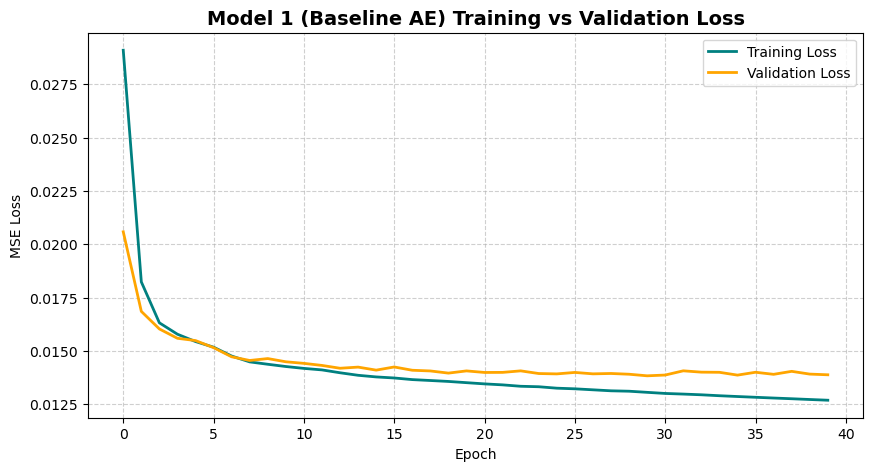

Average Training Loss   : 0.0142
Average Validation Loss : 0.0145


In [23]:
def plot_loss(history, title):
    plt.figure(figsize=(10,5))
    plt.plot(history['loss'], label='Training Loss', color='teal', linewidth=2)
    plt.plot(history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
    plt.title(f'{title} Training vs Validation Loss', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

plot_loss(history_model1, 'Model 1 (Baseline AE)')
print(f"Average Training Loss   : {np.mean(history_model1['loss']):.4f}")
print(f"Average Validation Loss : {np.mean(history_model1['val_loss']):.4f}")

#### **B.3 Evaluasi With SSM**

In [24]:
def evaluate_ssim(model, X_test_t, name='Model'):
    model.eval()
    with torch.no_grad():
        recon = model(X_test_t.to(device)).cpu().numpy()
    orig = X_test_t.numpy()
    scores = [ssim(orig[i,0], recon[i,0], data_range=1.0) for i in range(len(orig))]
    print(f'  {name}: Mean SSIM = {np.mean(scores):.4f} (std={np.std(scores):.4f})')
    return np.mean(scores), recon

In [25]:
ssim_model1, recon_model1 = evaluate_ssim(model1, X_test_t, 'Model 1 (Baseline)')

  Model 1 (Baseline): Mean SSIM = 0.5305 (std=0.1864)


**Reconstruct**

In [28]:
def show_reconstruction(X_test_t, recon, n=8, title='Rekonstruksi'):
    orig = X_test_t.numpy()
    plt.figure(figsize=(n*1.5, 4.5))
    for i in range(n):
        plt.subplot(2, n, i+1); plt.imshow(orig[i,0], cmap='gray'); plt.axis('off')
        if i==0: plt.title('Asli', loc='left')
        plt.subplot(2, n, n+i+1); plt.imshow(recon[i,0], cmap='gray'); plt.axis('off')
        if i==0: plt.title('Rekonstruksi', loc='left')
    plt.suptitle(title, fontweight='bold')
    plt.tight_layout() 
    plt.show()

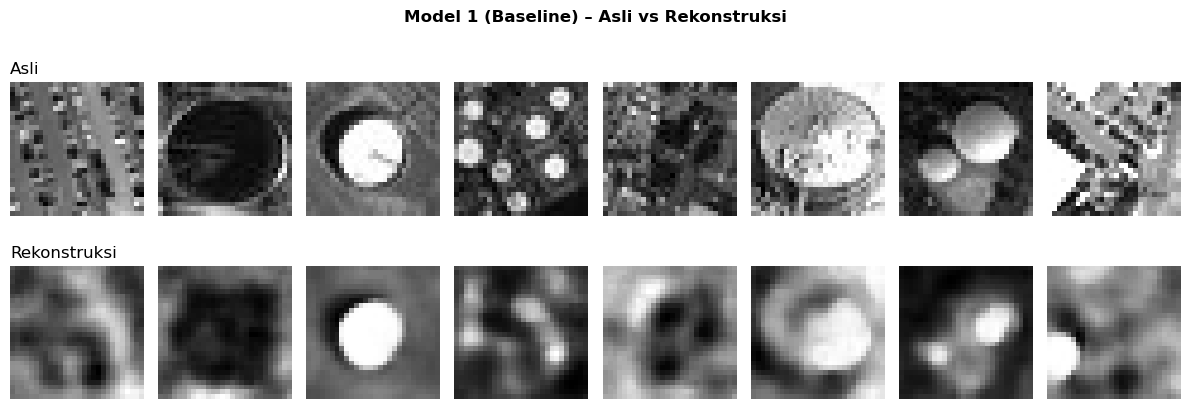

In [29]:
show_reconstruction(X_test_t, recon_model1, title='Model 1 (Baseline) – Asli vs Rekonstruksi')

### **C.  modifikasi arsitektur Autoencoder di atas agar mendapatkan representasi Dimension Reduction yang optimal dengan membandingkan hasil Structural Similarity Index (SSIM) nya**

#### **C.1 Model 2 (Modified)**

In [ ]:
class Modified(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),  
        )
        self.enc_fc = nn.Sequential(nn.Linear(7*7*64, latent_dim), nn.ReLU())
        self.dec_fc = nn.Sequential(nn.Linear(latent_dim, 7*7*64), nn.ReLU())
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 2, stride=2), nn.BatchNorm2d(32), nn.ReLU(), 
            nn.ConvTranspose2d(32, 16, 2, stride=2), nn.BatchNorm2d(16), nn.ReLU(), 
            nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid()
        )
    def encode(self, x): return self.enc_fc(self.enc(x).view(x.size(0), -1))
    def decode(self, z): return self.dec(self.dec_fc(z).view(-1, 64, 7, 7))
    def forward(self, x): return self.decode(self.encode(x))

In [ ]:
model2 = Modified(128).to(device)
print(f'Modified parameter: {sum(p.numel() for p in model2.parameters()):,}')

Modified parameter: 835,617


#### **C.2 Training Model Modified**

In [35]:
def train_m(model, train_loader, val_loader, epochs=60, lr=1e-3, patience=12):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.3, patience=5)
    history = {'loss': [], 'val_loss': []}
    best_val, best_state, wait = float('inf'), None, 0
    for ep in range(epochs):
        model.train(); tr = 0
        for xb, _ in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad(); loss = criterion(model(xb), xb); loss.backward(); optimizer.step()
            tr += loss.item()*xb.size(0)
        tr /= len(train_loader.dataset)
        model.eval(); vl = 0
        with torch.no_grad():
            for xb, _ in val_loader:
                xb = xb.to(device); vl += criterion(model(xb), xb).item()*xb.size(0)
        vl /= len(val_loader.dataset); scheduler.step(vl)
        history['loss'].append(tr); history['val_loss'].append(vl)
        if (ep+1)%5==0 or ep==0: print(f'  Epoch {ep+1:3d}/{epochs} | loss={tr:.5f} | val_loss={vl:.5f}')
        if vl < best_val: best_val, best_state, wait = vl, {k:v.cpu().clone() for k,v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: print(f'  Early stopping di epoch {ep+1}'); break
    if best_state: model.load_state_dict(best_state)
    return history

In [ ]:
history_model2 = train_m(model2, train_loader, val_loader, epochs=60)

  Epoch   1/60 | loss=0.02530 | val_loss=0.01839
  Epoch   5/60 | loss=0.01345 | val_loss=0.01285
  Epoch  10/60 | loss=0.01235 | val_loss=0.01329
  Epoch  15/60 | loss=0.01203 | val_loss=0.01203
  Epoch  20/60 | loss=0.01188 | val_loss=0.01220
  Epoch  25/60 | loss=0.01175 | val_loss=0.01173
  Epoch  30/60 | loss=0.01158 | val_loss=0.01174
  Epoch  35/60 | loss=0.01150 | val_loss=0.01155
  Epoch  40/60 | loss=0.01139 | val_loss=0.01157
  Epoch  45/60 | loss=0.01101 | val_loss=0.01133
  Epoch  50/60 | loss=0.01100 | val_loss=0.01135
  Epoch  55/60 | loss=0.01086 | val_loss=0.01125
  Epoch  60/60 | loss=0.01084 | val_loss=0.01122


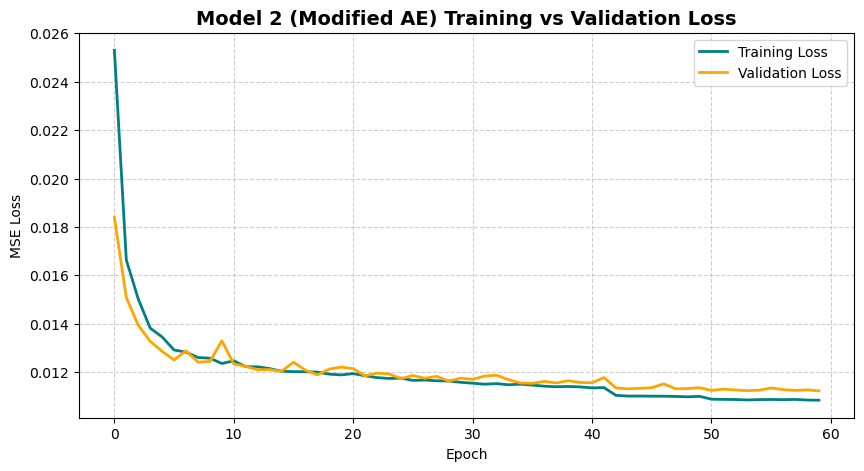

Average Training Loss   : 0.0120
Average Validation Loss : 0.0120


In [37]:
plot_loss(history_model2, 'Model 2 (Modified AE)')
print(f"Average Training Loss   : {np.mean(history_model2['loss']):.4f}")
print(f"Average Validation Loss : {np.mean(history_model2['val_loss']):.4f}")

#### **C.3 Evaluasi Model 2 with SSIM**

In [38]:
ssim_model2, recon_model2 = evaluate_ssim(model2, X_test_t, 'Model 2 (Modified)')

  Model 2 (Modified): Mean SSIM = 0.6124 (std=0.1724)


**Reconstruct**

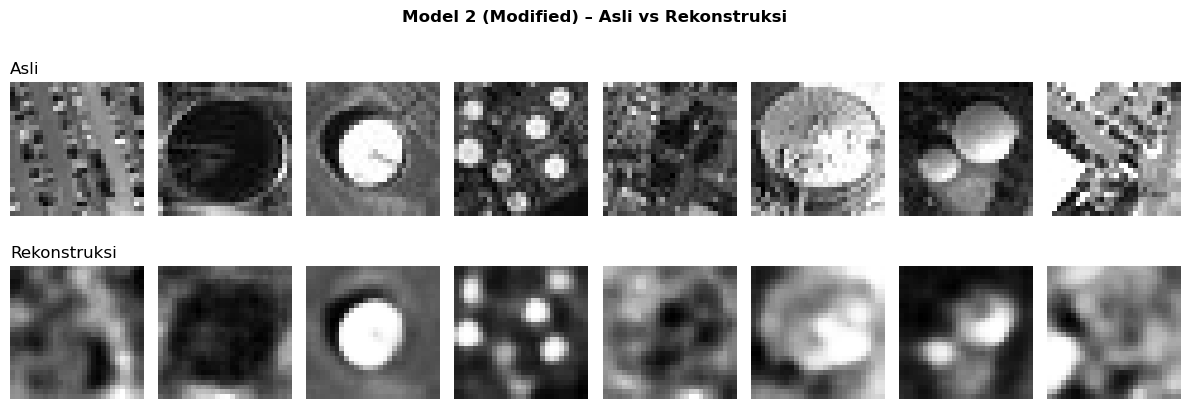

In [39]:
show_reconstruction(X_test_t, recon_model2, title='Model 2 (Modified) – Asli vs Rekonstruksi')

In [42]:
import pandas as pd
df_ssim = pd.DataFrame({
    'Model': ['Model 1 (Baseline)', 'Model 2 (Modified)'],
    'Mean SSIM': [ssim_model1, ssim_model2],
    'Latent Dim': [128, 128]
})
df_ssim['Peningkatan'] = ['—', f'+{(ssim_model2-ssim_model1):.4f} ({(ssim_model2-ssim_model1)/ssim_model1*100:+.1f}%)']
display(df_ssim.set_index('Model').style.format({'Mean SSIM':'{:.4f}'}).set_caption('Perbandingan SSIM – Baseline vs Modified'))

,Mean SSIM,Latent Dim,Peningkatan
Model,,,
Model 1 (Baseline),0.5305,128,—
Model 2 (Modified),0.6124,128,+0.0819 (+15.4%)


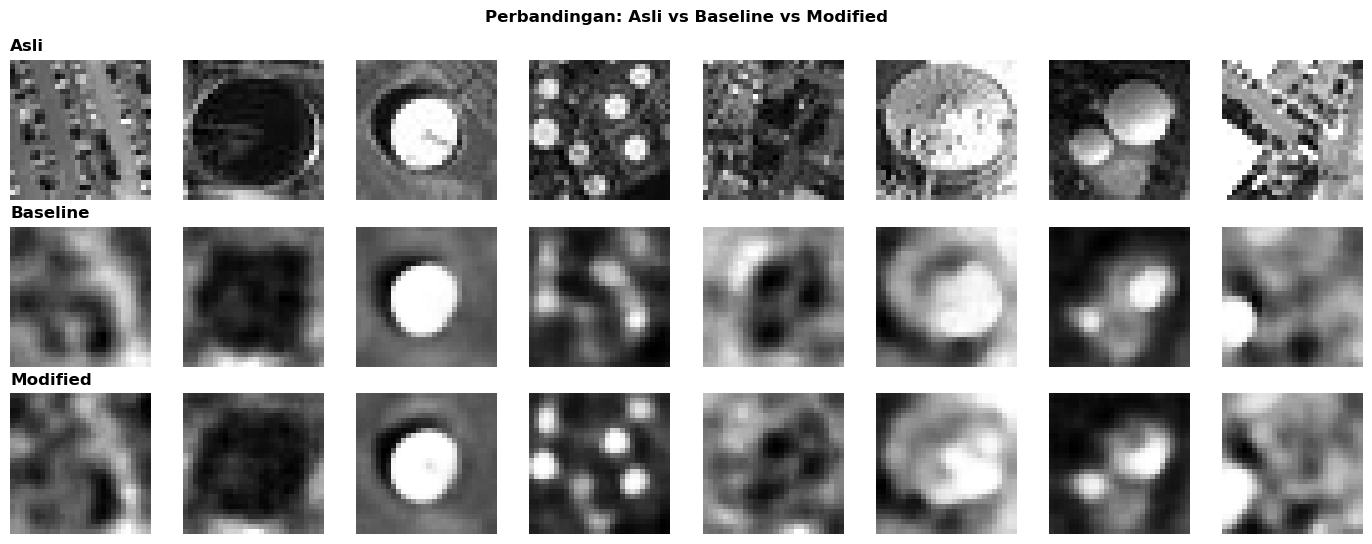

In [43]:
ground_truth = X_test_t.numpy()
plt.figure(figsize=(14, 5.5))
for i in range(8):
    plt.subplot(3, 8, i+1); plt.imshow(ground_truth[i,0], cmap='gray'); plt.axis('off')
    if i==0: plt.title('Asli', loc='left', fontweight='bold')
    plt.subplot(3, 8, 8+i+1); plt.imshow(recon_model1[i,0], cmap='gray'); plt.axis('off')
    if i==0: plt.title('Baseline', loc='left', fontweight='bold')
    plt.subplot(3, 8, 16+i+1); plt.imshow(recon_model2[i,0], cmap='gray'); plt.axis('off')
    if i==0: plt.title('Modified', loc='left', fontweight='bold')
plt.suptitle('Perbandingan: Asli vs Baseline vs Modified', fontweight='bold')
plt.tight_layout(); plt.show()